# VAE && CVAE(Conv VAE)

In [ ]:
!pip install numpy==1.21.5

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

In [11]:
# ==========================================
# 1. 定义超参数
# ==========================================
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
EPOCHS = 15
LATENT_DIM = 30  # 隐变量 z 的维度
IMAGE_SIZE = 28 * 28  # MNIST 图片展平后的维度 (784)

In [12]:
# ==========================================
# 2. 定义 VAE 模型
# ==========================================
class VAE(nn.Module):
    def __init__(self):
        super(VAE, self).__init__()

        # --- 编码器 (Encoder) ---
        # 输入 x -> 输出 mu 和 log_var
        self.fc1 = nn.Linear(IMAGE_SIZE, 400)
        self.fc_mu = nn.Linear(400, LATENT_DIM)      # 均值 mu
        self.fc_log_var = nn.Linear(400, LATENT_DIM) # 对数方差 log(sigma^2)

        # --- 解码器 (Decoder) ---
        # 输入 z -> 输出重构的图片 x_hat
        self.fc3 = nn.Linear(LATENT_DIM, 400)
        self.fc4 = nn.Linear(400, IMAGE_SIZE)

        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid() # 输出像素值在 [0, 1] 之间

    def encode(self, x):
        h = self.relu(self.fc1(x))
        return self.fc_mu(h), self.fc_log_var(h)

    def reparameterize(self, mu, log_var):
        """
        【核心】重参数化技巧 (Reparameterization Trick)
        z = mu + sigma * epsilon
        注意：这里使用的是标准正态分布的噪声 epsilon ~ N(0, I)
        """
        std = torch.exp(0.5 * log_var)  # 从 log(sigma^2) 还原出 sigma
        eps = torch.randn_like(std)     # 生成与 std 形状相同的标准正态噪声
        return mu + eps * std

    def decode(self, z):
        h = self.relu(self.fc3(z))
        return self.sigmoid(self.fc4(h))

    def forward(self, x):
        mu, log_var = self.encode(x)
        z = self.reparameterize(mu, log_var) # 关键步骤：采样 z
        x_recon = self.decode(z)
        return x_recon, mu, log_var

In [13]:
# ==========================================
# 2. 定义卷积 VAE 模型 (CVAE)
# ==========================================
class ConvVAE(nn.Module):
    def __init__(self):
        super(ConvVAE, self).__init__()

        # --- 编码器 (Encoder) ---
        # 输入: (N, 1, 28, 28)
        # 输出: (N, 64, 7, 7) -> 展平后映射到 mu 和 log_var
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1),   # (N, 32, 14, 14)
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),  # (N, 64, 7, 7)
            nn.ReLU()
        )
        
        # 7*7*64 = 3136
        self.fc_mu = nn.Linear(64 * 7 * 7, LATENT_DIM)
        self.fc_log_var = nn.Linear(64 * 7 * 7, LATENT_DIM)

        # --- 解码器 (Decoder) ---
        # 输入: z (N, LATENT_DIM)
        # 第一步：将 z 映射回特征图形状 (N, 64, 7, 7)
        self.fc_decode = nn.Linear(LATENT_DIM, 64 * 7 * 7)
        
        # 第二步：通过转置卷积逐步还原图片
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1), # (N, 32, 14, 14)
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=4, stride=2, padding=1),  # (N, 1, 28, 28)
            nn.Sigmoid() # 输出像素值在 [0, 1]
        )

    def encode(self, x):
        h = self.encoder(x)
        h = h.view(h.size(0), -1) # 展平为 (N, 3136)
        return self.fc_mu(h), self.fc_log_var(h)

    def reparameterize(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.fc_decode(z)
        h = h.view(h.size(0), 64, 7, 7) # 重塑为特征图 (N, 64, 7, 7)
        return self.decoder(h)

    def forward(self, x):
        mu, log_var = self.encode(x)
        z = self.reparameterize(mu, log_var)
        x_recon = self.decode(z)
        return x_recon, mu, log_var

In [16]:
# ==========================================
# 3. 定义损失函数 (Loss Function)
# ==========================================
def loss_function(recon_x, x, mu, log_var):
    """
    VAE 的总损失 = 重构损失 + KL 散度
    """
    # A. 重构损失 (Reconstruction Loss)
    # 对应公式: -E[log p(x|z)]
    # 对于二值图像(MNIST)，通常使用二元交叉熵 (BCE)
    BCE = nn.functional.binary_cross_entropy(recon_x, x, reduction='sum')

    # B. KL 散度 (KL Divergence)
    # 对应公式: 0.5 * sum(mu^2 + sigma^2 - log(sigma^2) - 1)
    # 这里的 log_var 就是 log(sigma^2)
    KLD = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())

    return 0.3*BCE + KLD

Epoch [1/15], Loss: 57.1888
Epoch [2/15], Loss: 45.9380
Epoch [3/15], Loss: 44.6980
Epoch [4/15], Loss: 44.0971
Epoch [5/15], Loss: 43.7250


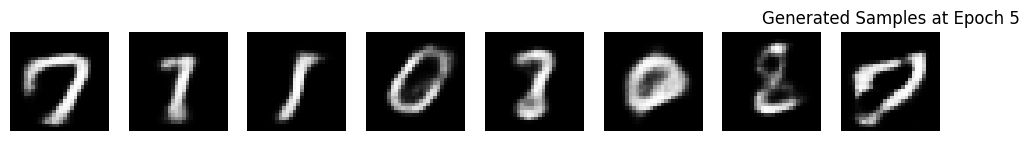

Epoch [6/15], Loss: 43.4125
Epoch [7/15], Loss: 43.1744
Epoch [8/15], Loss: 42.9557
Epoch [9/15], Loss: 42.8129
Epoch [10/15], Loss: 42.6803


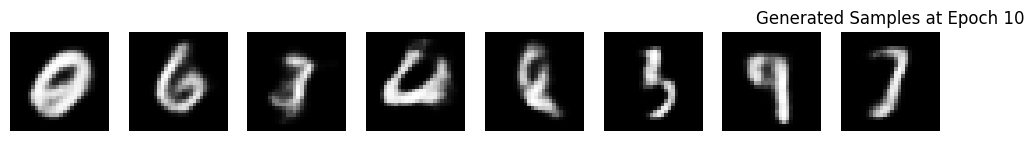

Epoch [11/15], Loss: 42.5417
Epoch [12/15], Loss: 42.4127
Epoch [13/15], Loss: 42.3120
Epoch [14/15], Loss: 42.2274
Epoch [15/15], Loss: 42.1423


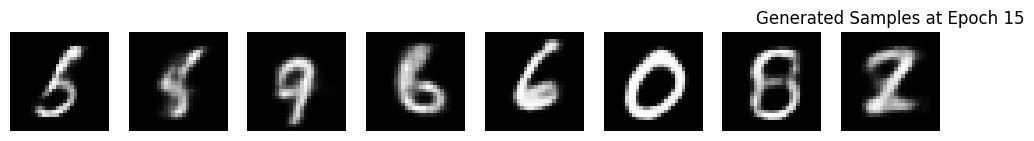

In [17]:
# ==========================================
# 4. 训练流程
# ==========================================
def train():
    transform = transforms.ToTensor()
    train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = ConvVAE().to(device)
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    model.train()
    for epoch in range(EPOCHS):
        total_loss = 0
        for batch_idx, (data, _) in enumerate(train_loader):
            data = data.to(device) # 注意：这里不需要 view(-1, 784)，保持四维张量
            
            optimizer.zero_grad()
            recon_batch, mu, log_var = model(data)
            
            # 计算损失时，recon_batch 是 (N,1,28,28)，需要展平与 data 对比
            loss = loss_function(recon_batch, data, mu, log_var)
            
            loss.backward()
            total_loss += loss.item()
            optimizer.step()

        print(f'Epoch [{epoch+1}/{EPOCHS}], Loss: {total_loss / len(train_loader.dataset):.4f}')
        
        # 可视化生成结果
        if (epoch + 1) % 5 == 0: # 每5个epoch显示一次
            with torch.no_grad():
                sample_z = torch.randn(8, LATENT_DIM).to(device)
                samples = model.decode(sample_z).cpu()
                
                fig, axes = plt.subplots(1, 8, figsize=(12, 2))
                for i in range(8):
                    axes[i].imshow(samples[i].squeeze(), cmap='gray')
                    axes[i].axis('off')
                plt.title(f'Generated Samples at Epoch {epoch+1}')
                plt.show()

if __name__ == "__main__":
    train()